In [3]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [5]:
example_data = "/Users/qmoreau/Documents/ERN_sim/N2pipeline/cong_incong_epochs/sub-AG05AS29_target_cong_incong-epo.fif"
# load epochs
epochs = mne.read_epochs(example_data, preload=True)

epochs

Reading /Users/qmoreau/Documents/ERN_sim/N2pipeline/cong_incong_epochs/sub-AG05AS29_target_cong_incong-epo.fif ...
    Found the data of interest:
        t =   -5000.00 ...    5000.00 ms
        0 CTF compensation matrices available
Not setting metadata
189 matching events found
No baseline correction applied
0 projection items activated


Number of events,189
Events,104: 46134: 143
Time range,-5.000 – 5.000 s
Baseline,-0.200 – 0.000 s


Number of congruent trials: 143
Number of incongruent trials: 46


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_84778/847521332.py:11: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  data_incong = epochs_incong.copy().pick([channel]).get_data()[:, 0, :]
/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_84778/847521332.py:12: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  data_cong = epochs_cong.copy().pick([channel]).get_data()[:, 0, :]


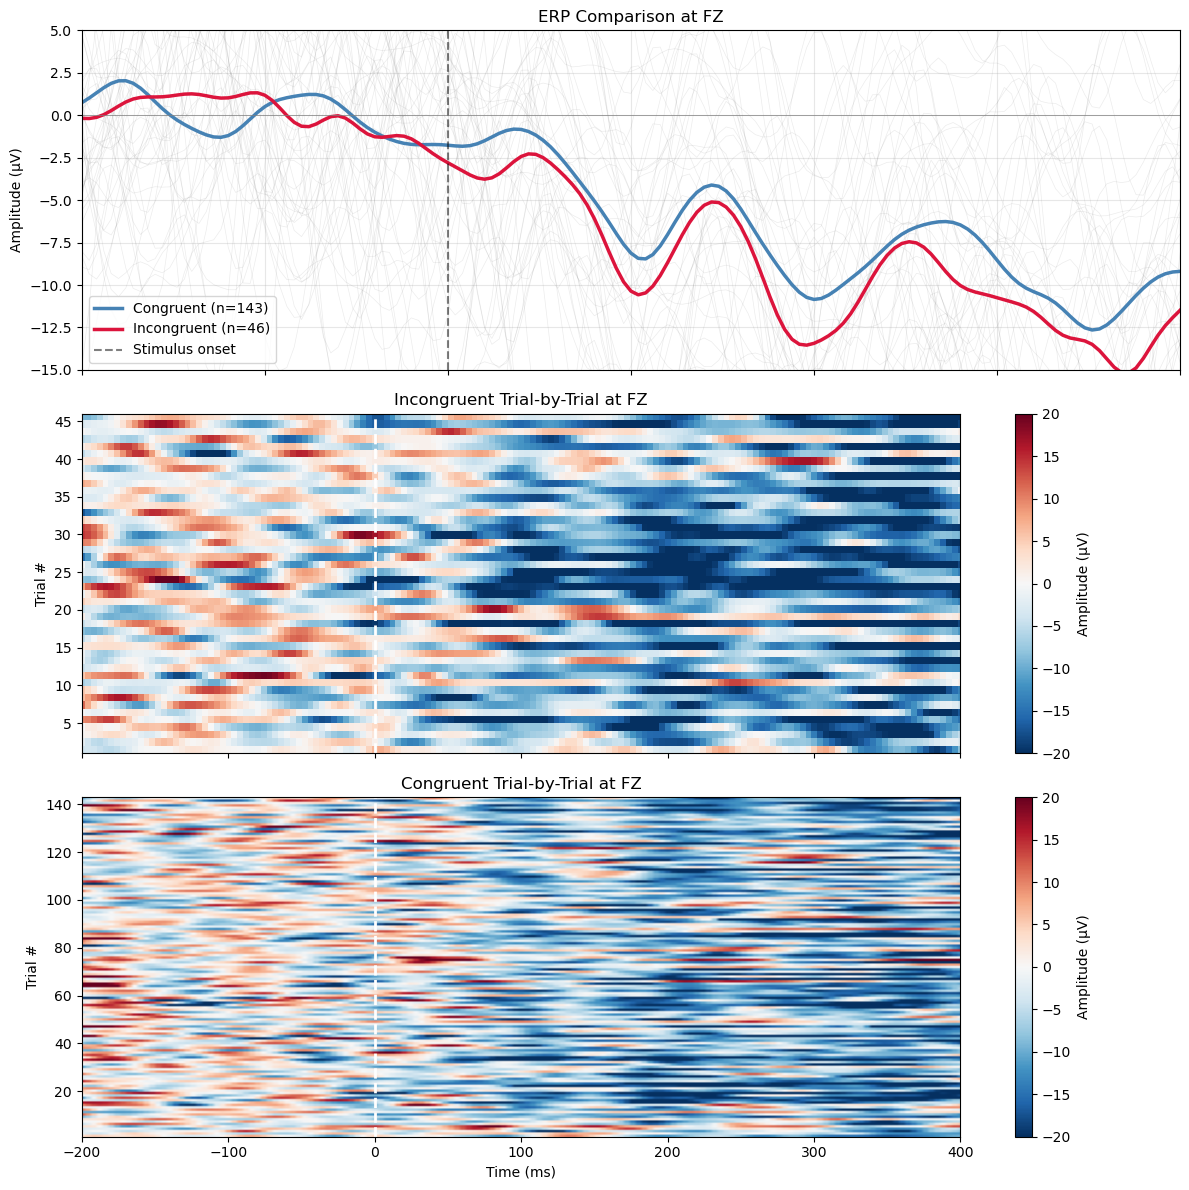

In [12]:
# Extract trials
epochs_incong = epochs['104'] 
epochs_cong = epochs['134']

print(f"Number of congruent trials: {len(epochs_cong)}")
print(f"Number of incongruent trials: {len(epochs_incong)}")

channel = 'FZ'

# Get data: trials x times
data_incong = epochs_incong.copy().pick([channel]).get_data()[:, 0, :]
data_cong = epochs_cong.copy().pick([channel]).get_data()[:, 0, :]
times = epochs_incong.times

# Grand averages
grand_avg_incong = data_incong.mean(axis=0)
grand_avg_cong = data_cong.mean(axis=0)

# Convert to microvolts
data_incong_uv = data_incong * 1e6
data_cong_uv = data_cong * 1e6
grand_avg_incong_uv = grand_avg_incong * 1e6
grand_avg_cong_uv = grand_avg_cong * 1e6

# Plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# Single trials + both grand averages
ax1.plot(times * 1000, data_incong_uv.T, 'gray', alpha=0.15, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_cong_uv, 'steelblue', linewidth=2.5, label=f'Congruent (n={len(epochs_cong)})')
ax1.plot(times * 1000, grand_avg_incong_uv, 'crimson', linewidth=2.5, label=f'Incongruent (n={len(epochs_incong)})')
ax1.axvline(0, color='k', linestyle='--', alpha=0.5, label='Stimulus onset')
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'ERP Comparison at {channel}')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlim([times[0] * 1000, times[-1] * 1000])
ax1.set_ylim([-15, 5])

# Heatmap - Incongruent
im2 = ax2.imshow(data_incong_uv, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, len(epochs_incong)],
                 cmap='RdBu_r', vmin=-20, vmax=20)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_ylabel('Trial #')
ax2.set_xlim([times[1200] * 1000, times[1350] * 1000])
ax2.set_title(f'Incongruent Trial-by-Trial at {channel}')
plt.colorbar(im2, ax=ax2, label='Amplitude (µV)')

# Heatmap - Congruent
im3 = ax3.imshow(data_cong_uv, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, len(epochs_cong)],
                 cmap='RdBu_r', vmin=-20, vmax=20)
ax3.axvline(0, color='white', linestyle='--', linewidth=2)
ax3.set_xlabel('Time (ms)')
ax3.set_ylabel('Trial #')
ax3.set_xlim([times[1200] * 1000, times[1350] * 1000])
ax3.set_title(f'Congruent Trial-by-Trial at {channel}')
plt.colorbar(im3, ax=ax3, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

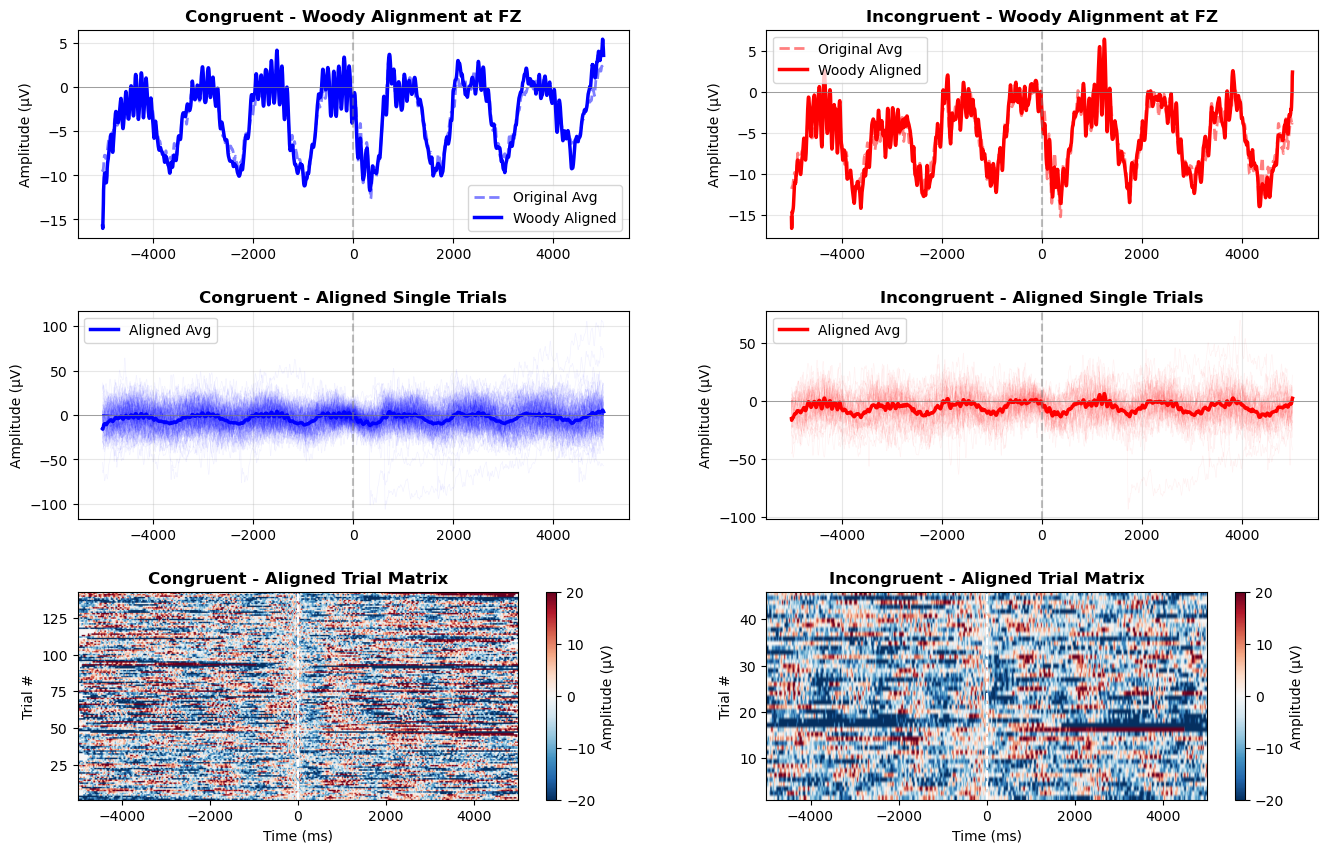


Congruent detected lags: Mean=4.76 samples, SD=29.25 samples
Incongruent detected lags: Mean=1.93 samples, SD=20.72 samples


In [16]:
from woody_filter import woody

sfreq = epochs.info['sfreq']
n_trials_incong = len(epochs_incong)
n_trials_cong = len(epochs_cong)

# Apply Woody filter to INCONGRUENT trials
data_incong_T = data_incong_uv.T  # Shape: (n_timepoints, n_trials)
aligned_avg_incong, detected_lags_incong = woody(
    data_incong_T,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=100

)

# Reconstruct individual aligned incongruent trials
aligned_trials_incong = np.zeros_like(data_incong_uv)
for i in range(n_trials_incong):
    lag = detected_lags_incong[i]
    if lag > 0:
        aligned_trials_incong[i, lag:] = data_incong_uv[i, :-lag]
    elif lag < 0:
        aligned_trials_incong[i, :lag] = data_incong_uv[i, -lag:]
    else:
        aligned_trials_incong[i, :] = data_incong_uv[i, :]

# Apply Woody filter to CONGRUENT trials
data_cong_T = data_cong_uv.T
aligned_avg_cong, detected_lags_cong = woody(
    data_cong_T,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=100
)

# Reconstruct individual aligned congruent trials
aligned_trials_cong = np.zeros_like(data_cong_uv)
for i in range(n_trials_cong):
    lag = detected_lags_cong[i]
    if lag > 0:
        aligned_trials_cong[i, lag:] = data_cong_uv[i, :-lag]
    elif lag < 0:
        aligned_trials_cong[i, :lag] = data_cong_uv[i, -lag:]
    else:
        aligned_trials_cong[i, :] = data_cong_uv[i, :]

# Plot Woody results
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# Row 1: Aligned grand averages comparison
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, grand_avg_cong_uv, 'b--', linewidth=2, alpha=0.5, label='Original Avg')
ax1.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Woody Aligned')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Congruent - Woody Alignment at {channel}', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, grand_avg_incong_uv, 'r--', linewidth=2, alpha=0.5, label='Original Avg')
ax2.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Woody Aligned')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Amplitude (µV)')
ax2.set_title(f'Incongruent - Woody Alignment at {channel}', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Aligned single trials
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(times * 1000, aligned_trials_cong.T, 'b', alpha=0.05, linewidth=0.5)
ax3.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Aligned Avg')
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax3.set_ylabel('Amplitude (µV)')
ax3.set_title('Congruent - Aligned Single Trials', fontweight='bold')
ax3.legend()
ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(times * 1000, aligned_trials_incong.T, 'r', alpha=0.05, linewidth=0.5)
ax4.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Aligned Avg')
ax4.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax4.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax4.set_ylabel('Amplitude (µV)')
ax4.set_title('Incongruent - Aligned Single Trials', fontweight='bold')
ax4.legend()
ax4.grid(alpha=0.3)

# Row 3: Trial matrices
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(aligned_trials_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials_cong],
                 cmap='RdBu_r', vmin=-20, vmax=20)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.set_xlabel('Time (ms)')
ax5.set_ylabel('Trial #')
ax5.set_title('Congruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Amplitude (µV)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(aligned_trials_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials_incong],
                 cmap='RdBu_r', vmin=-20, vmax=20)
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.set_xlabel('Time (ms)')
ax6.set_ylabel('Trial #')
ax6.set_title('Incongruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

# Print lag statistics
print(f"\nCongruent detected lags: Mean={detected_lags_cong.mean():.2f} samples, SD={detected_lags_cong.std():.2f} samples")
print(f"Incongruent detected lags: Mean={detected_lags_incong.mean():.2f} samples, SD={detected_lags_incong.std():.2f} samples")

In [22]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
from woody_filter import woody

# Suppress warnings
warnings.filterwarnings('ignore')

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw and Woody TFR for both conditions."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Check both conditions exist
    if '104' not in epochs.event_id or '134' not in epochs.event_id:
        return None
    
    epochs_incong = epochs['104']
    epochs_cong = epochs['134']
    
    n_trials_incong = len(epochs_incong)
    n_trials_cong = len(epochs_cong)
    
    if n_trials_incong < 5 or n_trials_cong < 5:
        return None
    
    # Get data
    data_incong = epochs_incong.copy().pick([channel]).get_data()[:, 0, :]
    data_cong = epochs_cong.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_incong.times
    data_incong_uv = data_incong * 1e6
    data_cong_uv = data_cong * 1e6
    sfreq = epochs_incong.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)
    
    def compute_tfr_trial(signal, freqs, n_cycles, sfreq):
        """Compute TFR for a single trial"""
        tfr = np.zeros((len(freqs), len(signal)))
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * \
                      np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(signal, wavelet, mode='same')
            tfr[idx, :] = np.abs(convolved) ** 2
        return tfr
    
    def process_condition(data_uv, n_trials, condition_name):
        """Process one condition (congruent or incongruent)"""
        
        # === RAW ANALYSIS ===
        grand_avg_raw = data_uv.mean(axis=0)
        
        # Total Power
        tfr_total_raw = np.zeros((len(freqs), len(times)))
        for trial in range(n_trials):
            tfr_total_raw += compute_tfr_trial(data_uv[trial, :], freqs, n_cycles, sfreq)
        tfr_total_raw /= n_trials
        
        # Evoked Power
        tfr_evoked_raw = compute_tfr_trial(grand_avg_raw, freqs, n_cycles, sfreq)
        
        # Induced Power
        tfr_induced_raw = tfr_total_raw - tfr_evoked_raw
        
        # Baseline correction
        bl_total = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
        bl_induced = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
        tfr_total_raw_pct = ((tfr_total_raw - bl_total) / bl_total) * 100
        tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced) / bl_induced) * 100
        
        # === WOODY ANALYSIS ===
        data_T = data_uv.T
        aligned_avg, detected_lags = woody(data_T, tol=0.1, max_it=100,
                                           est_mthd='woody', xcorr_mthd='unbiased',
                                           max_shift=100)  # LIMIT MAXIMUM SHIFT!
        
        # Reconstruct aligned trials IDENTICALLY to simulation
        aligned_trials = np.zeros_like(data_uv)
        for i in range(n_trials):
            lag = int(detected_lags[i])  # Ensure integer
            if lag > 0 and lag < len(times):
                aligned_trials[i, lag:] = data_uv[i, :-lag]
            elif lag < 0 and -lag < len(times):
                aligned_trials[i, :lag] = data_uv[i, -lag:]
            else:
                aligned_trials[i, :] = data_uv[i, :]
        
        # IDENTICAL TFR COMPUTATION TO RAW
        # Total Power (aligned)
        tfr_total_woody = np.zeros((len(freqs), len(times)))
        for trial in range(n_trials):
            tfr_total_woody += compute_tfr_trial(aligned_trials[trial, :], freqs, n_cycles, sfreq)
        tfr_total_woody /= n_trials
        
        # Evoked Power (aligned)
        tfr_evoked_woody = compute_tfr_trial(aligned_avg, freqs, n_cycles, sfreq)
        
        # Induced Power (aligned)
        tfr_induced_woody = tfr_total_woody - tfr_evoked_woody
        
        # Baseline correction
        bl_total_w = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
        bl_induced_w = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
        tfr_total_woody_pct = ((tfr_total_woody - bl_total_w) / bl_total_w) * 100
        tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_w) / bl_induced_w) * 100
        
        # Extract theta
        theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
        time_mask = (times >= time_window[0]) & (times <= time_window[1])
        
        return {
            'grand_avg_raw': grand_avg_raw,
            'grand_avg_woody': aligned_avg,
            'detected_lags': detected_lags,
            'tfr_total_raw_pct': tfr_total_raw_pct,
            'tfr_evoked_raw': tfr_evoked_raw,
            'tfr_induced_raw_pct': tfr_induced_raw_pct,
            'tfr_total_woody_pct': tfr_total_woody_pct,
            'tfr_evoked_woody': tfr_evoked_woody,
            'tfr_induced_woody_pct': tfr_induced_woody_pct,
            'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
            'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
            'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
            'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        }
    
    # Process both conditions
    results_incong = process_condition(data_incong_uv, n_trials_incong, 'incongruent')
    results_cong = process_condition(data_cong_uv, n_trials_cong, 'congruent')
    
    # Combine results
    results = {
        'n_trials_incong': n_trials_incong,
        'n_trials_cong': n_trials_cong,
        'times': times,
        'freqs': freqs,
        # Incongruent
        'incong_grand_avg_raw': results_incong['grand_avg_raw'],
        'incong_grand_avg_woody': results_incong['grand_avg_woody'],
        'incong_detected_lags': results_incong['detected_lags'],
        'incong_tfr_total_raw_pct': results_incong['tfr_total_raw_pct'],
        'incong_tfr_evoked_raw': results_incong['tfr_evoked_raw'],
        'incong_tfr_induced_raw_pct': results_incong['tfr_induced_raw_pct'],
        'incong_tfr_total_woody_pct': results_incong['tfr_total_woody_pct'],
        'incong_tfr_evoked_woody': results_incong['tfr_evoked_woody'],
        'incong_tfr_induced_woody_pct': results_incong['tfr_induced_woody_pct'],
        'incong_theta_total_raw': results_incong['theta_total_raw'],
        'incong_theta_induced_raw': results_incong['theta_induced_raw'],
        'incong_theta_total_woody': results_incong['theta_total_woody'],
        'incong_theta_induced_woody': results_incong['theta_induced_woody'],
        # Congruent
        'cong_grand_avg_raw': results_cong['grand_avg_raw'],
        'cong_grand_avg_woody': results_cong['grand_avg_woody'],
        'cong_detected_lags': results_cong['detected_lags'],
        'cong_tfr_total_raw_pct': results_cong['tfr_total_raw_pct'],
        'cong_tfr_evoked_raw': results_cong['tfr_evoked_raw'],
        'cong_tfr_induced_raw_pct': results_cong['tfr_induced_raw_pct'],
        'cong_tfr_total_woody_pct': results_cong['tfr_total_woody_pct'],
        'cong_tfr_evoked_woody': results_cong['tfr_evoked_woody'],
        'cong_tfr_induced_woody_pct': results_cong['tfr_induced_woody_pct'],
        'cong_theta_total_raw': results_cong['theta_total_raw'],
        'cong_theta_induced_raw': results_cong['theta_induced_raw'],
        'cong_theta_total_woody': results_cong['theta_total_woody'],
        'cong_theta_induced_woody': results_cong['theta_induced_woody'],
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = [
    "sub-AH17AR05", "sub-AI09ID16", "sub-AL07NK06", "sub-AL08AS02",
    "sub-AR06AS06", "sub-AR10IO04", "sub-AT06ED25", "sub-AU09GE22",
    "sub-CH04ER19", "sub-CH05NK28", "sub-CH06UT07", "sub-CH07AD15",
    "sub-CH07NK17", "sub-CH07RK18", "sub-CH10NG24", "sub-CK04NS18",
    "sub-CK05EN08", "sub-CK06ED08", "sub-CK06US15", "sub-CK07NK21",
    "sub-DADARE11", "sub-DS08NK08", "sub-DT05AH09", "sub-DT05EV26",
    "sub-DT07ES22", "sub-DTINTZ10", "sub-EA06ER02", "sub-EK05AN14",
    "sub-EK06ER26", "sub-EK07CH24", "sub-EL04AM03", "sub-EL05JO26",
    "sub-EL06EL11", "sub-EL06LD17", "sub-EL06ST21", "sub-EL07EL14",
    "sub-EN04ER01", "sub-EN04ER14", "sub-EN05AN02", "sub-EN05ED14",
    "sub-EN05KT02", "sub-EN05US05", "sub-EN06AN21", "sub-EN08CH27",
    "sub-EP05EN09", "sub-ER03ER09", "sub-ER03LF17", "sub-ER04CH03",
    "sub-ER04ER12", "sub-ER04RT24", "sub-ER04ST03", "sub-ER05AN13",
    "sub-ER05AR27", "sub-ER05AS20", "sub-ER05AV01", "sub-ER05EL09",
    "sub-ER05EL26", "sub-ER05ER07", "sub-ER05IM29", "sub-ER05MA17",
    "sub-ER05NG11", "sub-ER05RI09", "sub-ER05RK06", "sub-ER05RT24",
    "sub-ER06AN07", "sub-ER06AN28", "sub-ER06EF14", "sub-ER06EL06",
    "sub-ER06EN03", "sub-ER06EN27", "sub-ER06ET15", "sub-ER06IM15",
    "sub-ER06IS22", "sub-ER06KR20", "sub-ER06NK09", "sub-ER06US24",
    "sub-ER07AS24", "sub-ER07EF15", "sub-ER07EN04", "sub-ER07ER23",
    "sub-ER07ER30", "sub-ER07ND12", "sub-ER07RL02", "sub-ER08AH23",
    "sub-ER08AS28", "sub-ER08EN05", "sub-ER08ER03", "sub-ER08RT29",
    "sub-ER09DO22", "sub-ER09NK30", "sub-ER09NZ11", "sub-ER10IG12",
    "sub-ES06ER27", "sub-ES06NK11", "sub-EV06AN16", "sub-EZ04SE15",
    "sub-FA04HU23", "sub-FE06AN24", "sub-GA04LI18", "sub-GA06OF10",
    "sub-GY06LO26", "sub-HEERLD19", "sub-HL09AN11", "sub-HR07ED31",
    "sub-IA05NS20", "sub-ID07EN28", "sub-IG06LF01", "sub-IG06NS07",
    "sub-IG06WE03", "sub-IG07RT16", "sub-IK06ET06", "sub-IK09LD05",
    "sub-IN05ED23", "sub-IN06AS14", "sub-IN07ET30", "sub-IR04ET20",
    "sub-IS06RG09", "sub-IT08ND26", "sub-JA06AS11", "sub-JU05IN24",
    "sub-KA04LF11", "sub-KE04NI10", "sub-KE05AN23", "sub-KE06EL16",
    "sub-KE07AN05", "sub-KE07ER04", "sub-KE08AS23", "sub-KI05US17",
    "sub-KN05EN09", "sub-KO07EL16", "sub-LA08RE26", "sub-LE04ON09",
    "sub-LF04AS01", "sub-LF07RT29", "sub-LO06RE10", "sub-LY07EL23",
    "sub-MA06LO21", "sub-ME05NS04", "sub-MI07AH25", "sub-NA04AV25",
    "sub-NA04OV25", "sub-ND05NG06", "sub-ND06EF01", "sub-NE06AS01",
    "sub-NE06AS31", "sub-NE06EL01", "sub-NG03YI17", "sub-NG05AS30",
    "sub-NG06NI21", "sub-NG06UL04", "sub-NG07AN22", "sub-NK06AS24",
    "sub-NK06RG30", "sub-NN04AN24", "sub-NN05AN05", "sub-NN05IR17",
    "sub-NN06TH16", "sub-NN06US23", "sub-NN07EN14", "sub-NN07ID18",
    "sub-NN08AS03", "sub-NN08EL29", "sub-NN08ER22", "sub-NN08LM06",
    "sub-NN09LM18", "sub-NN09NS31", "sub-NO05RT22", "sub-NS05RO15",
    "sub-NS09EL05", "sub-NY04DT26", "sub-NZ04EN16", "sub-NZ09ER04",
    "sub-OH05NK29", "sub-ON05EL22", "sub-ON06US07", "sub-OW07RK26",
    "sub-PP07AS29", "sub-RASUAN07", "sub-RF09EL18", "sub-RG05AS08",
    "sub-RG06AS09", "sub-RG07US04", "sub-RN10AN23", "sub-RS06RS22",
    "sub-RS07LF20", "sub-RT04KE01", "sub-RT05EL10", "sub-RT06AN02",
    "sub-RT07LD06", "sub-RZ05ND19", "sub-SE05EN28", "sub-SE05ZI24",
    "sub-SE06AM29", "sub-SE06NS17", "sub-SS04PH05", "sub-ST03ED03",
    "sub-ST07NK15", "sub-TA03RL11", "sub-TE03AS11", "sub-TE05AS09",
    "sub-TE05NS01", "sub-TE08IO29", "sub-TE10AN12", "sub-TH07AR12",
    "sub-TL08AN16", "sub-TT08NS17", "sub-TZ08US31", "sub-UN07AS25",
    "sub-US05RK06", "sub-US07US10", "sub-US08KE27", "sub-VA03ER17",
    "sub-VA05AS27", "sub-VA05ER28", "sub-VA05OR26", "sub-VA06EY24",
    "sub-VA06NZ29", "sub-VA06OV12", "sub-WA04EJ22", "sub-WA05EJ08",
    "sub-XX04AS28"
]

data_dir = Path("/Users/qmoreau/Documents/ERN_sim/N2pipeline/cong_incong_epochs")

# Analyze all subjects with progress bar
results_list = []
for subj in tqdm(subjects, desc="Analyzing subjects"):
    epochs_path = data_dir / f"{subj}_target_cong_incong-epo.fif"
    if not epochs_path.exists():
        continue
    result = analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
    if result is not None:
        result['subject'] = subj
        results_list.append(result)

print(f"\nAnalyzed {len(results_list)} subjects successfully")

Analyzing subjects: 100%|██████████| 221/221 [14:37<00:00,  3.97s/it]


Analyzed 216 subjects successfully


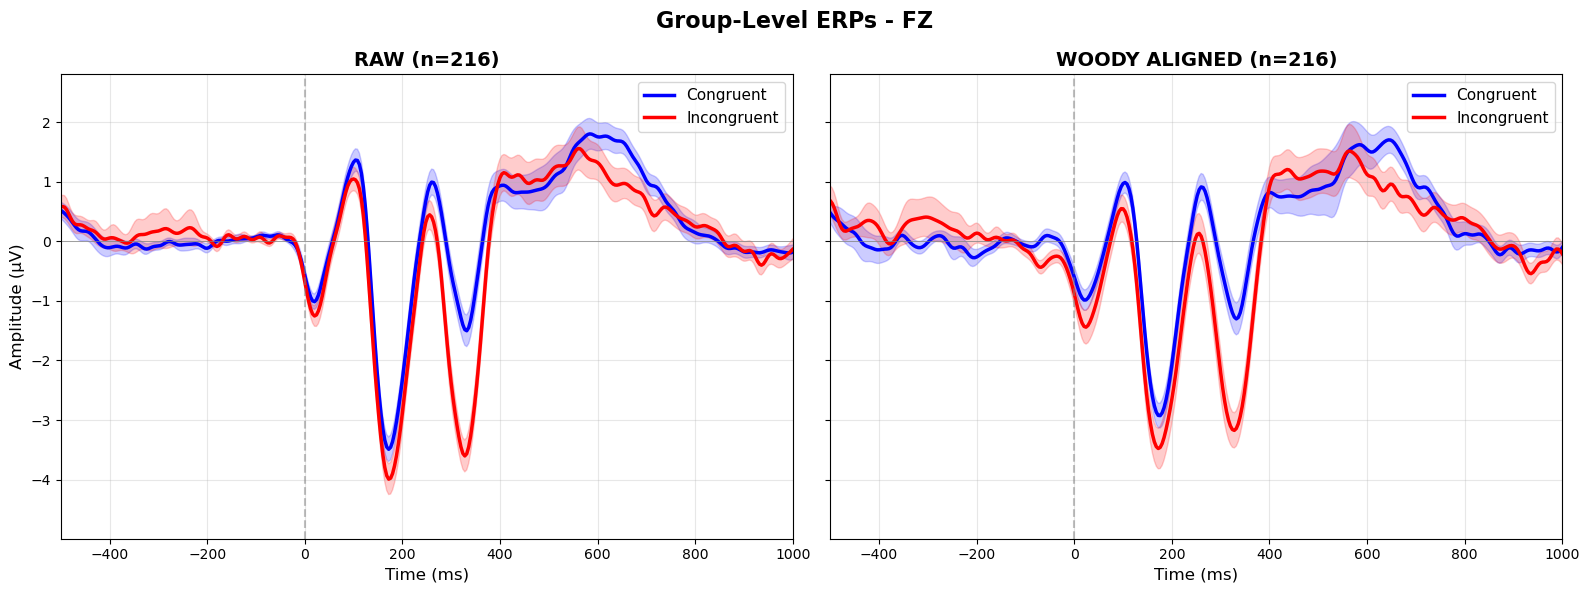

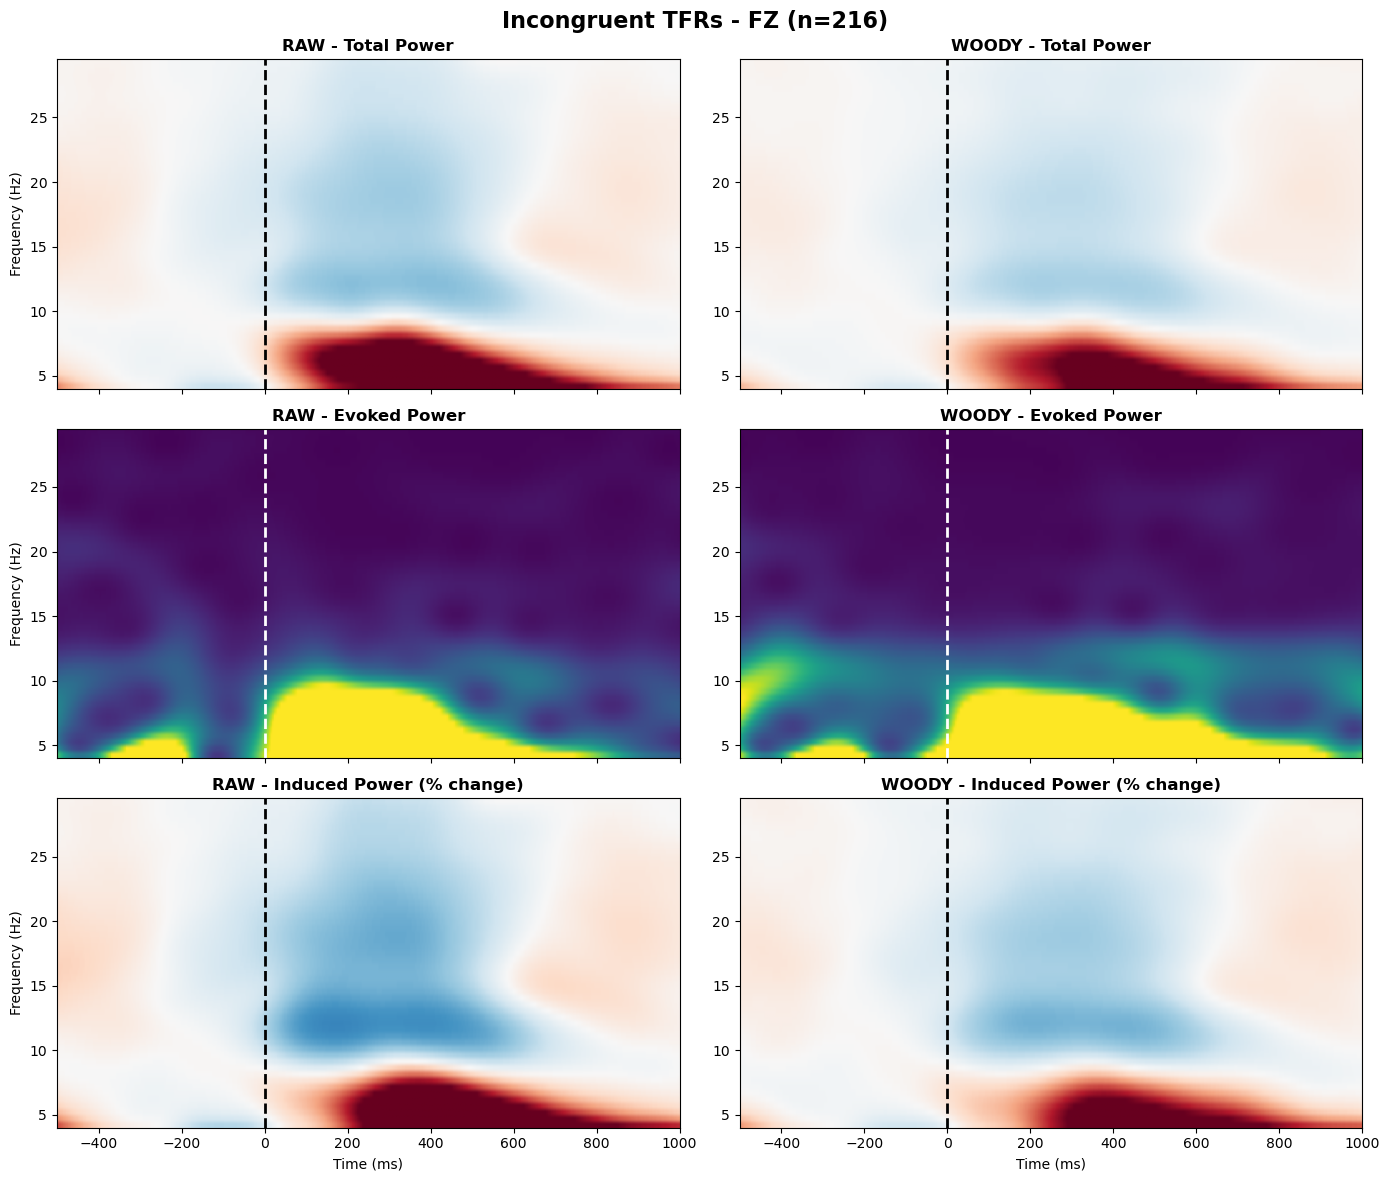

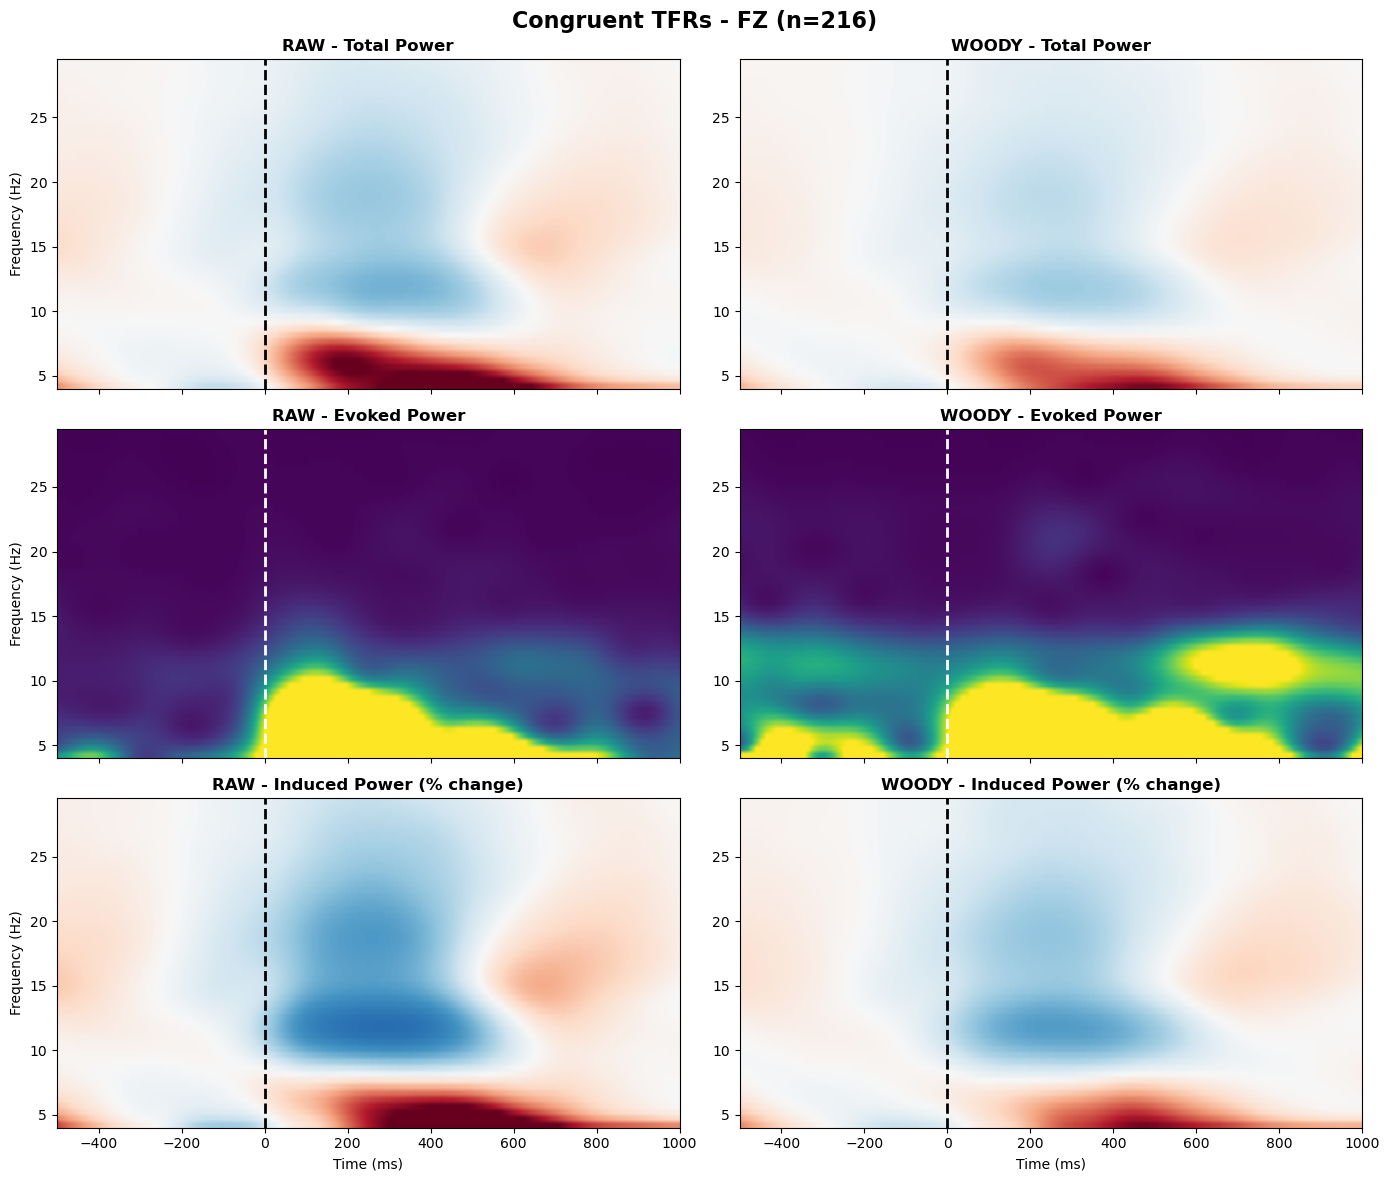

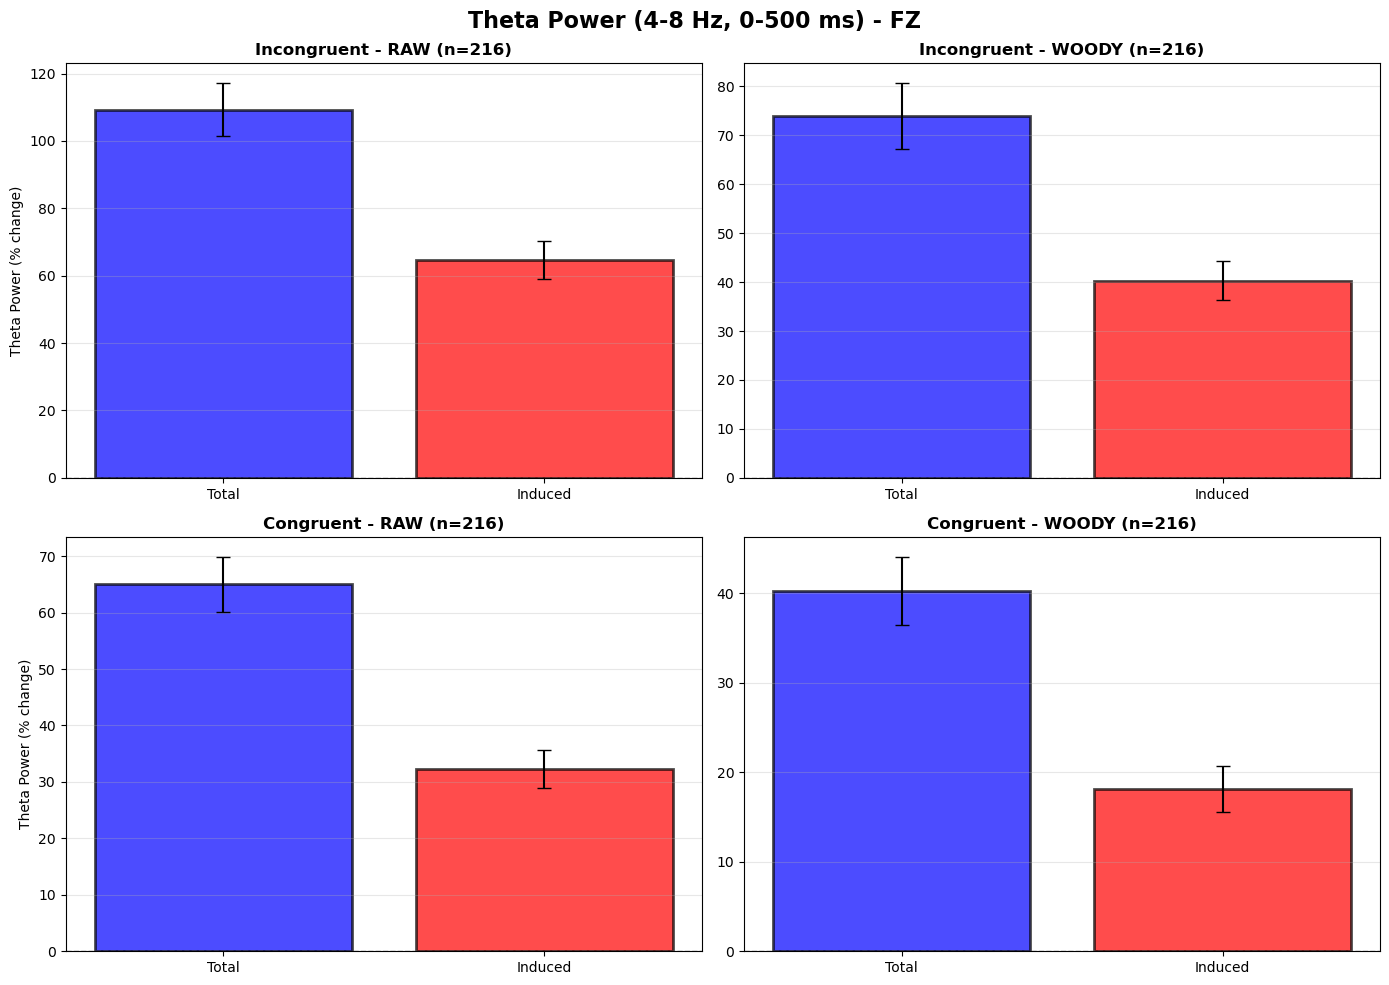


Saved ERP arrays: cong_erp_raw_mean.npy, incong_erp_raw_mean.npy, times.npy

=== SUMMARY STATISTICS ===
INCONGRUENT Raw - Total: 109.31±7.87%, Induced: 64.55±5.62%
INCONGRUENT Woody - Total: 73.99±6.69%, Induced: 40.31±4.00%
CONGRUENT Raw - Total: 64.98±4.94%, Induced: 32.28±3.35%
CONGRUENT Woody - Total: 40.26±3.83%, Induced: 18.13±2.52%

Results saved to 'flanker_theta_woody_analysis.csv' (216 subjects)


In [33]:
# === COMPUTE GROUP AVERAGES ===
times = results_list[0]['times']
freqs = results_list[0]['freqs']

# INCONGRUENT
incong_erp_raw_all = np.array([r['incong_grand_avg_raw'] for r in results_list])
incong_erp_woody_all = np.array([r['incong_grand_avg_woody'] for r in results_list])
incong_erp_raw_mean = incong_erp_raw_all.mean(axis=0)
incong_erp_raw_sem = incong_erp_raw_all.std(axis=0) / np.sqrt(len(results_list))
incong_erp_woody_mean = incong_erp_woody_all.mean(axis=0)
incong_erp_woody_sem = incong_erp_woody_all.std(axis=0) / np.sqrt(len(results_list))

incong_tfr_total_raw_mean = np.array([r['incong_tfr_total_raw_pct'] for r in results_list]).mean(axis=0)
incong_tfr_evoked_raw_mean = np.array([r['incong_tfr_evoked_raw'] for r in results_list]).mean(axis=0)
incong_tfr_induced_raw_mean = np.array([r['incong_tfr_induced_raw_pct'] for r in results_list]).mean(axis=0)
incong_tfr_total_woody_mean = np.array([r['incong_tfr_total_woody_pct'] for r in results_list]).mean(axis=0)
incong_tfr_evoked_woody_mean = np.array([r['incong_tfr_evoked_woody'] for r in results_list]).mean(axis=0)
incong_tfr_induced_woody_mean = np.array([r['incong_tfr_induced_woody_pct'] for r in results_list]).mean(axis=0)

# CONGRUENT
cong_erp_raw_all = np.array([r['cong_grand_avg_raw'] for r in results_list])
cong_erp_woody_all = np.array([r['cong_grand_avg_woody'] for r in results_list])
cong_erp_raw_mean = cong_erp_raw_all.mean(axis=0)
cong_erp_raw_sem = cong_erp_raw_all.std(axis=0) / np.sqrt(len(results_list))
cong_erp_woody_mean = cong_erp_woody_all.mean(axis=0)
cong_erp_woody_sem = cong_erp_woody_all.std(axis=0) / np.sqrt(len(results_list))

cong_tfr_total_raw_mean = np.array([r['cong_tfr_total_raw_pct'] for r in results_list]).mean(axis=0)
cong_tfr_evoked_raw_mean = np.array([r['cong_tfr_evoked_raw'] for r in results_list]).mean(axis=0)
cong_tfr_induced_raw_mean = np.array([r['cong_tfr_induced_raw_pct'] for r in results_list]).mean(axis=0)
cong_tfr_total_woody_mean = np.array([r['cong_tfr_total_woody_pct'] for r in results_list]).mean(axis=0)
cong_tfr_evoked_woody_mean = np.array([r['cong_tfr_evoked_woody'] for r in results_list]).mean(axis=0)
cong_tfr_induced_woody_mean = np.array([r['cong_tfr_induced_woody_pct'] for r in results_list]).mean(axis=0)

# === PLOT 1: ERPs - RAW vs WOODY (OVERLAID) ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Determine common y-limits
all_erps = np.concatenate([cong_erp_raw_mean, incong_erp_raw_mean, 
                           cong_erp_woody_mean, incong_erp_woody_mean])
ylim_min = all_erps.min() - 1
ylim_max = all_erps.max() + 1

# Raw
ax1.plot(times * 1000, cong_erp_raw_mean, 'b', linewidth=2.5, label='Congruent')
ax1.fill_between(times * 1000, cong_erp_raw_mean - cong_erp_raw_sem, 
                 cong_erp_raw_mean + cong_erp_raw_sem, color='b', alpha=0.2)
ax1.plot(times * 1000, incong_erp_raw_mean, 'r', linewidth=2.5, label='Incongruent')
ax1.fill_between(times * 1000, incong_erp_raw_mean - incong_erp_raw_sem,
                 incong_erp_raw_mean + incong_erp_raw_sem, color='r', alpha=0.2)
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylim([ylim_min, ylim_max])
ax1.set_xlabel('Time (ms)', fontsize=12)
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'RAW (n={len(results_list)})', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

# Woody
ax2.plot(times * 1000, cong_erp_woody_mean, 'b', linewidth=2.5, label='Congruent')
ax2.fill_between(times * 1000, cong_erp_woody_mean - cong_erp_woody_sem,
                 cong_erp_woody_mean + cong_erp_woody_sem, color='b', alpha=0.2)
ax2.plot(times * 1000, incong_erp_woody_mean, 'r', linewidth=2.5, label='Incongruent')
ax2.fill_between(times * 1000, incong_erp_woody_mean - incong_erp_woody_sem,
                 incong_erp_woody_mean + incong_erp_woody_sem, color='r', alpha=0.2)
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylim([ylim_min, ylim_max])
ax2.set_xlabel('Time (ms)', fontsize=12)
ax2.set_title(f'WOODY ALIGNED (n={len(results_list)})', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# === PLOT 2: TFRs INCONGRUENT - RAW vs WOODY ===
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)

# Compute shared limits for each row - BETTER SCALING
vmax_total = 100  # Symmetric for % change
vmax_evoked = max(np.percentile(incong_tfr_evoked_raw_mean, 95), 
                  np.percentile(incong_tfr_evoked_woody_mean, 95))

# Use percentile for induced to avoid outliers making plot too white
vmax_induced = max(np.percentile(np.abs(incong_tfr_induced_raw_mean), 95),
                   np.percentile(np.abs(incong_tfr_induced_woody_mean), 95))

# RAW
axes[0, 0].imshow(incong_tfr_total_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_total, vmax=vmax_total, cmap='RdBu_r')
axes[0, 0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0, 0].set_xlim([-500, 1000])
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('RAW - Total Power', fontweight='bold')

axes[1, 0].imshow(incong_tfr_evoked_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1, 0].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1, 0].set_xlim([-500, 1000])
axes[1, 0].set_ylabel('Frequency (Hz)')
axes[1, 0].set_title('RAW - Evoked Power', fontweight='bold')

axes[2, 0].imshow(incong_tfr_induced_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_induced, vmax=vmax_induced, cmap='RdBu_r')
axes[2, 0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2, 0].set_xlim([-500, 1000])
axes[2, 0].set_xlabel('Time (ms)')
axes[2, 0].set_ylabel('Frequency (Hz)')
axes[2, 0].set_title('RAW - Induced Power (% change)', fontweight='bold')

# WOODY
axes[0, 1].imshow(incong_tfr_total_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_total, vmax=vmax_total, cmap='RdBu_r')
axes[0, 1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0, 1].set_xlim([-500, 1000])
axes[0, 1].set_title('WOODY - Total Power', fontweight='bold')

axes[1, 1].imshow(incong_tfr_evoked_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1, 1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1, 1].set_xlim([-500, 1000])
axes[1, 1].set_title('WOODY - Evoked Power', fontweight='bold')

axes[2, 1].imshow(incong_tfr_induced_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_induced, vmax=vmax_induced, cmap='RdBu_r')
axes[2, 1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2, 1].set_xlim([-500, 1000])
axes[2, 1].set_xlabel('Time (ms)')
axes[2, 1].set_title('WOODY - Induced Power (% change)', fontweight='bold')

plt.suptitle(f'Incongruent TFRs - FZ (n={len(results_list)})', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# === PLOT 3: TFRs CONGRUENT - RAW vs WOODY ===
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)

# Compute shared limits for each row
vmax_total = 100
vmax_evoked = max(np.percentile(cong_tfr_evoked_raw_mean, 95), 
                  np.percentile(cong_tfr_evoked_woody_mean, 95))

# Use percentile for induced
vmax_induced = max(np.percentile(np.abs(cong_tfr_induced_raw_mean), 95),
                   np.percentile(np.abs(cong_tfr_induced_woody_mean), 95))

# RAW
axes[0, 0].imshow(cong_tfr_total_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_total, vmax=vmax_total, cmap='RdBu_r')
axes[0, 0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0, 0].set_xlim([-500, 1000])
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('RAW - Total Power', fontweight='bold')

axes[1, 0].imshow(cong_tfr_evoked_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1, 0].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1, 0].set_xlim([-500, 1000])
axes[1, 0].set_ylabel('Frequency (Hz)')
axes[1, 0].set_title('RAW - Evoked Power', fontweight='bold')

axes[2, 0].imshow(cong_tfr_induced_raw_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_induced, vmax=vmax_induced, cmap='RdBu_r')
axes[2, 0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2, 0].set_xlim([-500, 1000])
axes[2, 0].set_xlabel('Time (ms)')
axes[2, 0].set_ylabel('Frequency (Hz)')
axes[2, 0].set_title('RAW - Induced Power (% change)', fontweight='bold')

# WOODY
axes[0, 1].imshow(cong_tfr_total_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_total, vmax=vmax_total, cmap='RdBu_r')
axes[0, 1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0, 1].set_xlim([-500, 1000])
axes[0, 1].set_title('WOODY - Total Power', fontweight='bold')

axes[1, 1].imshow(cong_tfr_evoked_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1, 1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1, 1].set_xlim([-500, 1000])
axes[1, 1].set_title('WOODY - Evoked Power', fontweight='bold')

axes[2, 1].imshow(cong_tfr_induced_woody_mean, aspect='auto', origin='lower',
                  extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                  vmin=-vmax_induced, vmax=vmax_induced, cmap='RdBu_r')
axes[2, 1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2, 1].set_xlim([-500, 1000])
axes[2, 1].set_xlabel('Time (ms)')
axes[2, 1].set_title('WOODY - Induced Power (% change)', fontweight='bold')

plt.suptitle(f'Congruent TFRs - FZ (n={len(results_list)})', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# === PLOT 4: THETA BARPLOTS ===
df = pd.DataFrame(results_list)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Incongruent
incong_raw_means = [df['incong_theta_total_raw'].mean(), df['incong_theta_induced_raw'].mean()]
incong_raw_sems = [df['incong_theta_total_raw'].sem(), df['incong_theta_induced_raw'].sem()]
x_pos = np.arange(2)
axes[0, 0].bar(x_pos, incong_raw_means, yerr=incong_raw_sems, color=['blue', 'red'],
               alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(['Total', 'Induced'])
axes[0, 0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0, 0].set_ylabel('Theta Power (% change)')
axes[0, 0].set_title(f'Incongruent - RAW (n={len(df)})', fontweight='bold')
axes[0, 0].grid(alpha=0.3, axis='y')

incong_woody_means = [df['incong_theta_total_woody'].mean(), df['incong_theta_induced_woody'].mean()]
incong_woody_sems = [df['incong_theta_total_woody'].sem(), df['incong_theta_induced_woody'].sem()]
axes[0, 1].bar(x_pos, incong_woody_means, yerr=incong_woody_sems, color=['blue', 'red'],
               alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(['Total', 'Induced'])
axes[0, 1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0, 1].set_title(f'Incongruent - WOODY (n={len(df)})', fontweight='bold')
axes[0, 1].grid(alpha=0.3, axis='y')

# Congruent
cong_raw_means = [df['cong_theta_total_raw'].mean(), df['cong_theta_induced_raw'].mean()]
cong_raw_sems = [df['cong_theta_total_raw'].sem(), df['cong_theta_induced_raw'].sem()]
axes[1, 0].bar(x_pos, cong_raw_means, yerr=cong_raw_sems, color=['blue', 'red'],
               alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(['Total', 'Induced'])
axes[1, 0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1, 0].set_ylabel('Theta Power (% change)')
axes[1, 0].set_title(f'Congruent - RAW (n={len(df)})', fontweight='bold')
axes[1, 0].grid(alpha=0.3, axis='y')

cong_woody_means = [df['cong_theta_total_woody'].mean(), df['cong_theta_induced_woody'].mean()]
cong_woody_sems = [df['cong_theta_total_woody'].sem(), df['cong_theta_induced_woody'].sem()]
axes[1, 1].bar(x_pos, cong_woody_means, yerr=cong_woody_sems, color=['blue', 'red'],
               alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(['Total', 'Induced'])
axes[1, 1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1, 1].set_title(f'Congruent - WOODY (n={len(df)})', fontweight='bold')
axes[1, 1].grid(alpha=0.3, axis='y')

plt.suptitle('Theta Power (4-8 Hz, 0-500 ms) - FZ', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Save ERPs as numpy arrays
np.save('cong_erp_raw_mean.npy', cong_erp_raw_mean)
np.save('incong_erp_raw_mean.npy', incong_erp_raw_mean)
np.save('times.npy', times)
print("\nSaved ERP arrays: cong_erp_raw_mean.npy, incong_erp_raw_mean.npy, times.npy")

print("\n=== SUMMARY STATISTICS ===")
print(f"INCONGRUENT Raw - Total: {incong_raw_means[0]:.2f}±{incong_raw_sems[0]:.2f}%, Induced: {incong_raw_means[1]:.2f}±{incong_raw_sems[1]:.2f}%")
print(f"INCONGRUENT Woody - Total: {incong_woody_means[0]:.2f}±{incong_woody_sems[0]:.2f}%, Induced: {incong_woody_means[1]:.2f}±{incong_woody_sems[1]:.2f}%")
print(f"CONGRUENT Raw - Total: {cong_raw_means[0]:.2f}±{cong_raw_sems[0]:.2f}%, Induced: {cong_raw_means[1]:.2f}±{cong_raw_sems[1]:.2f}%")
print(f"CONGRUENT Woody - Total: {cong_woody_means[0]:.2f}±{cong_woody_sems[0]:.2f}%, Induced: {cong_woody_means[1]:.2f}±{cong_woody_sems[1]:.2f}%")

# Save results
df.to_csv('flanker_theta_woody_analysis.csv', index=False)
print(f"\nResults saved to 'flanker_theta_woody_analysis.csv' ({len(df)} subjects)")

Number of subjects: 216

=== PAIRED T-TEST RESULTS ===

Raw (No Alignment):
  Incongruent: M = 64.55, SD = 82.65
  Congruent:   M = 32.28, SD = 49.19
  t(215) = 8.938, p = 0.0000, d = 0.608

Woody Filter (Aligned):
  Incongruent: M = 40.31, SD = 58.83
  Congruent:   M = 18.13, SD = 37.01
  t(215) = 8.037, p = 0.0000, d = 0.547


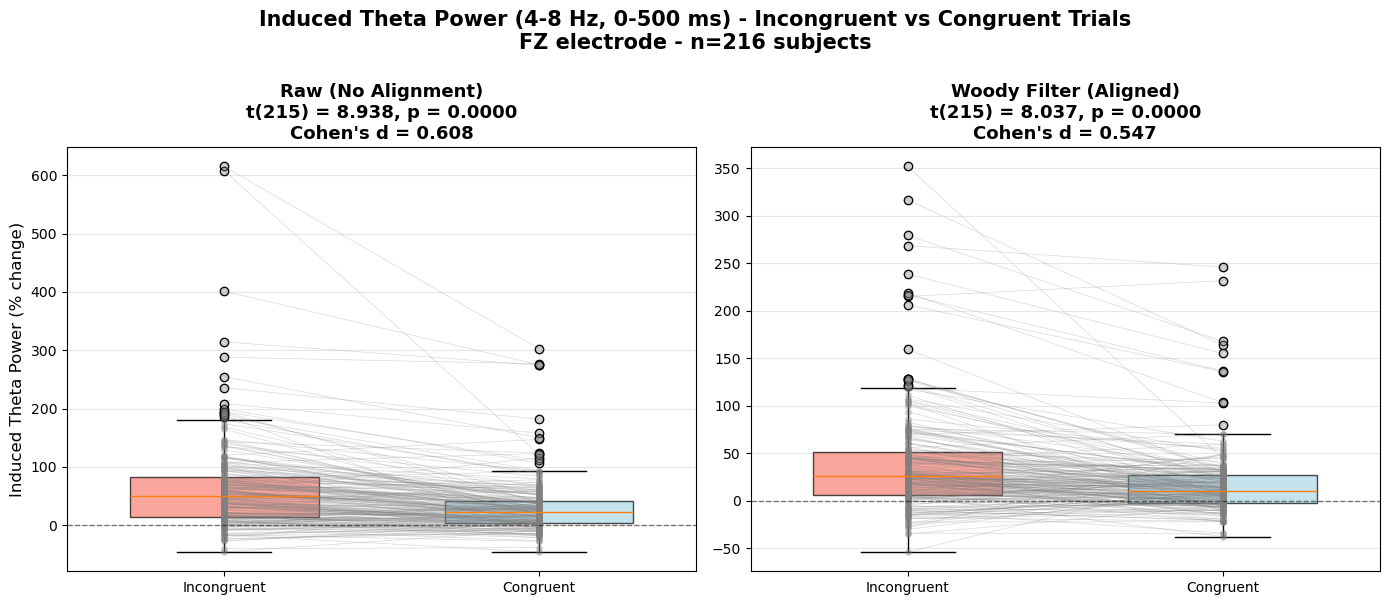

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# Load results from Flanker analysis
df = pd.read_csv('flanker_theta_woody_analysis.csv')

print(f"Number of subjects: {len(df)}")

# Perform paired t-tests
# Raw (no alignment)
t_raw, p_raw = stats.ttest_rel(df['incong_theta_induced_raw'], 
                                df['cong_theta_induced_raw'])

# Woody filtered
t_woody, p_woody = stats.ttest_rel(df['incong_theta_induced_woody'], 
                                    df['cong_theta_induced_woody'])

# Calculate effect sizes (Cohen's d for paired samples)
def cohens_d_paired(x, y):
    diff = x - y
    return diff.mean() / diff.std()

d_raw = cohens_d_paired(df['incong_theta_induced_raw'], 
                        df['cong_theta_induced_raw'])
d_woody = cohens_d_paired(df['incong_theta_induced_woody'], 
                          df['cong_theta_induced_woody'])

# Print statistics
print("\n=== PAIRED T-TEST RESULTS ===")
print(f"\nRaw (No Alignment):")
print(f"  Incongruent: M = {df['incong_theta_induced_raw'].mean():.2f}, SD = {df['incong_theta_induced_raw'].std():.2f}")
print(f"  Congruent:   M = {df['cong_theta_induced_raw'].mean():.2f}, SD = {df['cong_theta_induced_raw'].std():.2f}")
print(f"  t({len(df)-1}) = {t_raw:.3f}, p = {p_raw:.4f}, d = {d_raw:.3f}")

print(f"\nWoody Filter (Aligned):")
print(f"  Incongruent: M = {df['incong_theta_induced_woody'].mean():.2f}, SD = {df['incong_theta_induced_woody'].std():.2f}")
print(f"  Congruent:   M = {df['cong_theta_induced_woody'].mean():.2f}, SD = {df['cong_theta_induced_woody'].std():.2f}")
print(f"  t({len(df)-1}) = {t_woody:.3f}, p = {p_woody:.4f}, d = {d_woody:.3f}")

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Prepare data for boxplots
data_raw = [df['incong_theta_induced_raw'], df['cong_theta_induced_raw']]
data_woody = [df['incong_theta_induced_woody'], df['cong_theta_induced_woody']]

# Raw boxplot
bp1 = axes[0].boxplot(data_raw, labels=['Incongruent', 'Congruent'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp1['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df)):
    axes[0].plot([1, 2], 
                [df['incong_theta_induced_raw'].iloc[i], 
                 df['cong_theta_induced_raw'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[0].set_ylabel('Induced Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nt({len(df)-1}) = {t_raw:.3f}, p = {p_raw:.4f}\nCohen\'s d = {d_raw:.3f}', 
                 fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

# Woody boxplot
bp2 = axes[1].boxplot(data_woody, labels=['Incongruent', 'Congruent'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp2['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df)):
    axes[1].plot([1, 2], 
                [df['incong_theta_induced_woody'].iloc[i], 
                 df['cong_theta_induced_woody'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[1].set_title(f'Woody Filter (Aligned)\nt({len(df)-1}) = {t_woody:.3f}, p = {p_woody:.4f}\nCohen\'s d = {d_woody:.3f}', 
                 fontsize=13, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

plt.suptitle(f'Induced Theta Power (4-8 Hz, 0-500 ms) - Incongruent vs Congruent Trials\nFZ electrode - n={len(df)} subjects', 
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

In [30]:
import sys
sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')

from lagged_autocoherence import lagged_hilbert_autocoherence


In [31]:
def analyze_subject_induced_autocoherence_flanker(epochs_path, freqs_range, lags_range, time_window=(-5, 5)):
    """
    Compute autocoherence for raw induced and Woody induced trials.
    """
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Check both conditions exist
    if '104' not in epochs.event_id or '134' not in epochs.event_id:
        return None
    
    epochs_incong = epochs['104']
    epochs_cong = epochs['134']
    
    n_trials_incong = len(epochs_incong)
    n_trials_cong = len(epochs_cong)
    
    if n_trials_incong < 10 or n_trials_cong < 10:
        return None
    
    # Get data
    data_incong = epochs_incong.copy().pick(['FZ']).get_data()[:, 0, :]
    data_cong = epochs_cong.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_incong.times
    data_incong_uv = data_incong * 1e6
    data_cong_uv = data_cong * 1e6
    sfreq = epochs_incong.info['sfreq']
    
    # Crop to time window
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    def process_condition(data_uv, n_trials, condition_name):
        """Process one condition"""
        
        # Crop data
        data_cropped = data_uv[:, time_mask]
        
        # === RAW INDUCED (subtract grand average) ===
        grand_avg_raw = data_cropped.mean(axis=0)
        data_induced_raw = data_cropped - grand_avg_raw
        
        # === WOODY INDUCED (align, then subtract aligned grand average) ===
        # Apply Woody filter on full data
        data_T = data_uv.T
        aligned_avg, detected_lags = woody(
            data_T,
            tol=0.1,
            max_it=100,
            est_mthd='woody',
            xcorr_mthd='unbiased',
            max_shift=50
        )
        
        # Reconstruct aligned trials
        aligned_trials = np.zeros_like(data_uv)
        for i in range(n_trials):
            lag = int(detected_lags[i])
            if lag > 0 and lag < len(times):
                aligned_trials[i, lag:] = data_uv[i, :-lag]
            elif lag < 0 and -lag < len(times):
                aligned_trials[i, :lag] = data_uv[i, -lag:]
            else:
                aligned_trials[i, :] = data_uv[i, :]
        
        # Crop aligned trials
        data_woody_cropped = aligned_trials[:, time_mask]
        
        # Subtract aligned grand average
        grand_avg_woody = data_woody_cropped.mean(axis=0)
        data_induced_woody = data_woody_cropped - grand_avg_woody
        
        # === COMPUTE AUTOCOHERENCE ===
        lcs_induced_raw = lagged_hilbert_autocoherence(
            data_induced_raw,
            freqs_range,
            lags_range,
            srate=sfreq,
            df=1.0,
        )
        
        lcs_induced_woody = lagged_hilbert_autocoherence(
            data_induced_woody,
            freqs_range,
            lags_range,
            srate=sfreq,
            df=1.0,
        )
        
        return {
            'lcs_induced_raw': lcs_induced_raw,
            'lcs_induced_woody': lcs_induced_woody,
            'detected_lags': detected_lags,
        }
    
    # Process both conditions
    results_incong = process_condition(data_incong_uv, n_trials_incong, 'incongruent')
    results_cong = process_condition(data_cong_uv, n_trials_cong, 'congruent')
    
    results = {
        'subject': Path(epochs_path).stem.split('_')[0],
        'n_trials_incong': n_trials_incong,
        'n_trials_cong': n_trials_cong,
        # Incongruent
        'lcs_incong_raw': results_incong['lcs_induced_raw'],
        'lcs_incong_woody': results_incong['lcs_induced_woody'],
        'mean_lag_ms_incong': results_incong['detected_lags'].mean() / sfreq * 1000,
        'std_lag_ms_incong': results_incong['detected_lags'].std() / sfreq * 1000,
        # Congruent
        'lcs_cong_raw': results_cong['lcs_induced_raw'],
        'lcs_cong_woody': results_cong['lcs_induced_woody'],
        'mean_lag_ms_cong': results_cong['detected_lags'].mean() / sfreq * 1000,
        'std_lag_ms_cong': results_cong['detected_lags'].std() / sfreq * 1000,
    }
    
    return results


# === SETUP ===
subjects = [
    "sub-AH17AR05", "sub-AI09ID16", "sub-AL07NK06", "sub-AL08AS02",
    "sub-AR06AS06", "sub-AR10IO04", "sub-AT06ED25", "sub-AU09GE22",
    "sub-CH04ER19", "sub-CH05NK28", "sub-CH06UT07", "sub-CH07AD15",
    "sub-CH07NK17", "sub-CH07RK18", "sub-CH10NG24", "sub-CK04NS18",
    "sub-CK05EN08", "sub-CK06ED08", "sub-CK06US15", "sub-CK07NK21",
    "sub-DADARE11", "sub-DS08NK08", "sub-DT05AH09", "sub-DT05EV26",
    "sub-DT07ES22", "sub-DTINTZ10", "sub-EA06ER02", "sub-EK05AN14",
    "sub-EK06ER26", "sub-EK07CH24", "sub-EL04AM03", "sub-EL05JO26",
    "sub-EL06EL11", "sub-EL06LD17", "sub-EL06ST21", "sub-EL07EL14",
    "sub-EN04ER01", "sub-EN04ER14", "sub-EN05AN02", "sub-EN05ED14",
    "sub-EN05KT02", "sub-EN05US05", "sub-EN06AN21", "sub-EN08CH27",
    "sub-EP05EN09", "sub-ER03ER09", "sub-ER03LF17", "sub-ER04CH03",
    "sub-ER04ER12", "sub-ER04RT24", "sub-ER04ST03", "sub-ER05AN13",
    "sub-ER05AR27", "sub-ER05AS20", "sub-ER05AV01", "sub-ER05EL09",
    "sub-ER05EL26", "sub-ER05ER07", "sub-ER05IM29", "sub-ER05MA17",
    "sub-ER05NG11", "sub-ER05RI09", "sub-ER05RK06", "sub-ER05RT24",
    "sub-ER06AN07", "sub-ER06AN28", "sub-ER06EF14", "sub-ER06EL06",
    "sub-ER06EN03", "sub-ER06EN27", "sub-ER06ET15", "sub-ER06IM15",
    "sub-ER06IS22", "sub-ER06KR20", "sub-ER06NK09", "sub-ER06US24",
    "sub-ER07AS24", "sub-ER07EF15", "sub-ER07EN04", "sub-ER07ER23",
    "sub-ER07ER30", "sub-ER07ND12", "sub-ER07RL02", "sub-ER08AH23",
    "sub-ER08AS28", "sub-ER08EN05", "sub-ER08ER03", "sub-ER08RT29",
    "sub-ER09DO22", "sub-ER09NK30", "sub-ER09NZ11", "sub-ER10IG12",
    "sub-ES06ER27", "sub-ES06NK11", "sub-EV06AN16", "sub-EZ04SE15",
    "sub-FA04HU23", "sub-FE06AN24", "sub-GA04LI18", "sub-GA06OF10",
    "sub-GY06LO26", "sub-HEERLD19", "sub-HL09AN11", "sub-HR07ED31",
    "sub-IA05NS20", "sub-ID07EN28", "sub-IG06LF01", "sub-IG06NS07",
    "sub-IG06WE03", "sub-IG07RT16", "sub-IK06ET06", "sub-IK09LD05",
    "sub-IN05ED23", "sub-IN06AS14", "sub-IN07ET30", "sub-IR04ET20",
    "sub-IS06RG09", "sub-IT08ND26", "sub-JA06AS11", "sub-JU05IN24",
    "sub-KA04LF11", "sub-KE04NI10", "sub-KE05AN23", "sub-KE06EL16",
    "sub-KE07AN05", "sub-KE07ER04", "sub-KE08AS23", "sub-KI05US17",
    "sub-KN05EN09", "sub-KO07EL16", "sub-LA08RE26", "sub-LE04ON09",
    "sub-LF04AS01", "sub-LF07RT29", "sub-LO06RE10", "sub-LY07EL23",
    "sub-MA06LO21", "sub-ME05NS04", "sub-MI07AH25", "sub-NA04AV25",
    "sub-NA04OV25", "sub-ND05NG06", "sub-ND06EF01", "sub-NE06AS01",
    "sub-NE06AS31", "sub-NE06EL01", "sub-NG03YI17", "sub-NG05AS30",
    "sub-NG06NI21", "sub-NG06UL04", "sub-NG07AN22", "sub-NK06AS24",
    "sub-NK06RG30", "sub-NN04AN24", "sub-NN05AN05", "sub-NN05IR17",
    "sub-NN06TH16", "sub-NN06US23", "sub-NN07EN14", "sub-NN07ID18",
    "sub-NN08AS03", "sub-NN08EL29", "sub-NN08ER22", "sub-NN08LM06",
    "sub-NN09LM18", "sub-NN09NS31", "sub-NO05RT22", "sub-NS05RO15",
    "sub-NS09EL05", "sub-NY04DT26", "sub-NZ04EN16", "sub-NZ09ER04",
    "sub-OH05NK29", "sub-ON05EL22", "sub-ON06US07", "sub-OW07RK26",
    "sub-PP07AS29", "sub-RASUAN07", "sub-RF09EL18", "sub-RG05AS08",
    "sub-RG06AS09", "sub-RG07US04", "sub-RN10AN23", "sub-RS06RS22",
    "sub-RS07LF20", "sub-RT04KE01", "sub-RT05EL10", "sub-RT06AN02",
    "sub-RT07LD06", "sub-RZ05ND19", "sub-SE05EN28", "sub-SE05ZI24",
    "sub-SE06AM29", "sub-SE06NS17", "sub-SS04PH05", "sub-ST03ED03",
    "sub-ST07NK15", "sub-TA03RL11", "sub-TE03AS11", "sub-TE05AS09",
    "sub-TE05NS01", "sub-TE08IO29", "sub-TE10AN12", "sub-TH07AR12",
    "sub-TL08AN16", "sub-TT08NS17", "sub-TZ08US31", "sub-UN07AS25",
    "sub-US05RK06", "sub-US07US10", "sub-US08KE27", "sub-VA03ER17",
    "sub-VA05AS27", "sub-VA05ER28", "sub-VA05OR26", "sub-VA06EY24",
    "sub-VA06NZ29", "sub-VA06OV12", "sub-WA04EJ22", "sub-WA05EJ08",
    "sub-XX04AS28"
]

data_dir = Path("/Users/qmoreau/Documents/ERN_sim/N2pipeline/cong_incong_epochs")

freqs_range = np.arange(1, 30, 0.5)
lags_range = np.arange(0.5, 5, 0.25)

# Run analysis
all_results_flanker = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / f"{sub_id}_target_cong_incong-epo.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject_induced_autocoherence_flanker(sub_file, freqs_range, lags_range)
        if results is not None:
            all_results_flanker.append(results)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue

print(f"\nSuccessfully analyzed {len(all_results_flanker)} subjects")


Processing subjects: 100%|██████████| 221/221 [3:22:02<00:00, 54.86s/it]    


Successfully analyzed 216 subjects


Group statistics (INDUCED - INCONGRUENT):
  Raw induced - mean: 0.287, max: 0.986
  Woody induced - mean: 0.275, max: 0.985
  Difference - mean: 0.012, max: 0.037

Group statistics (INDUCED - CONGRUENT):
  Raw induced - mean: 0.289, max: 0.985
  Woody induced - mean: 0.276, max: 0.984
  Difference - mean: 0.013, max: 0.038


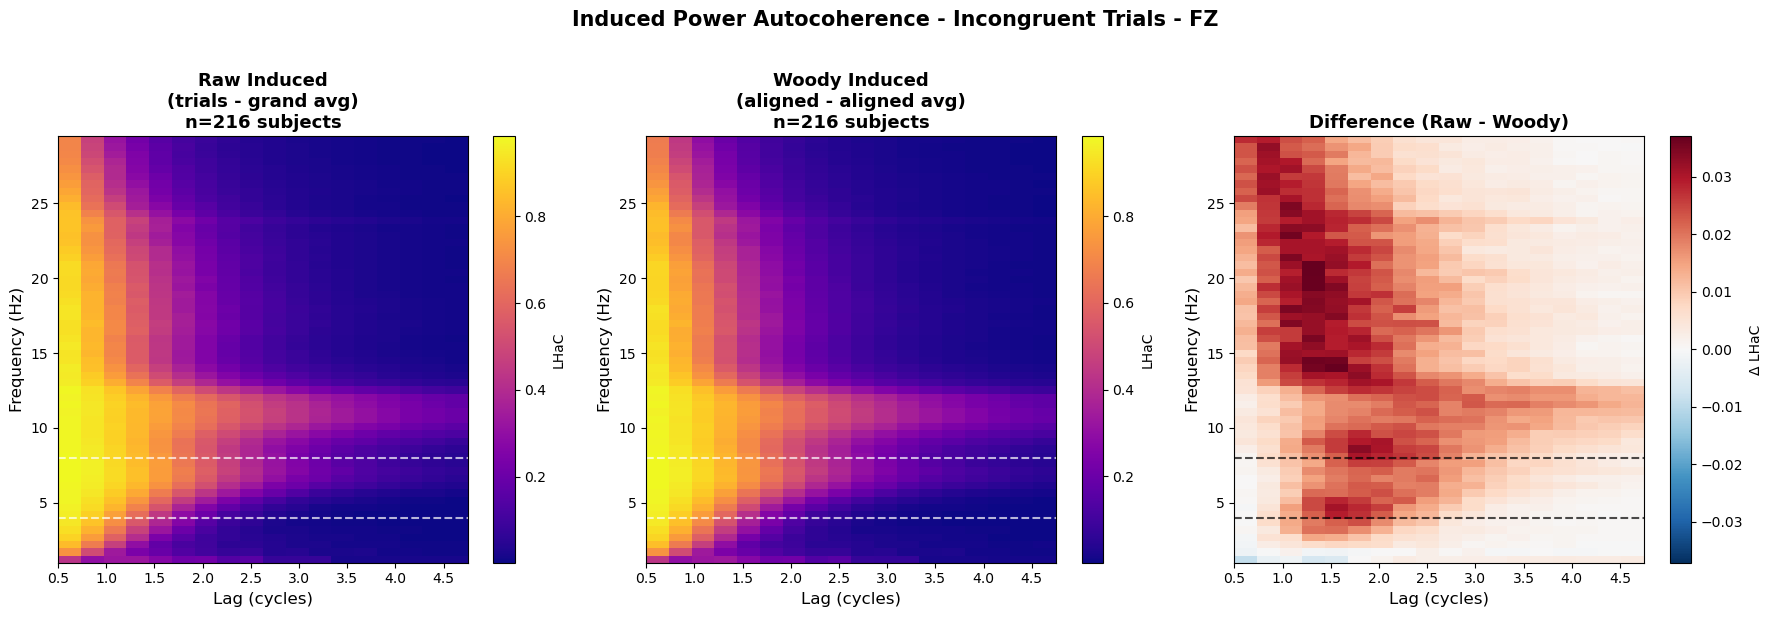

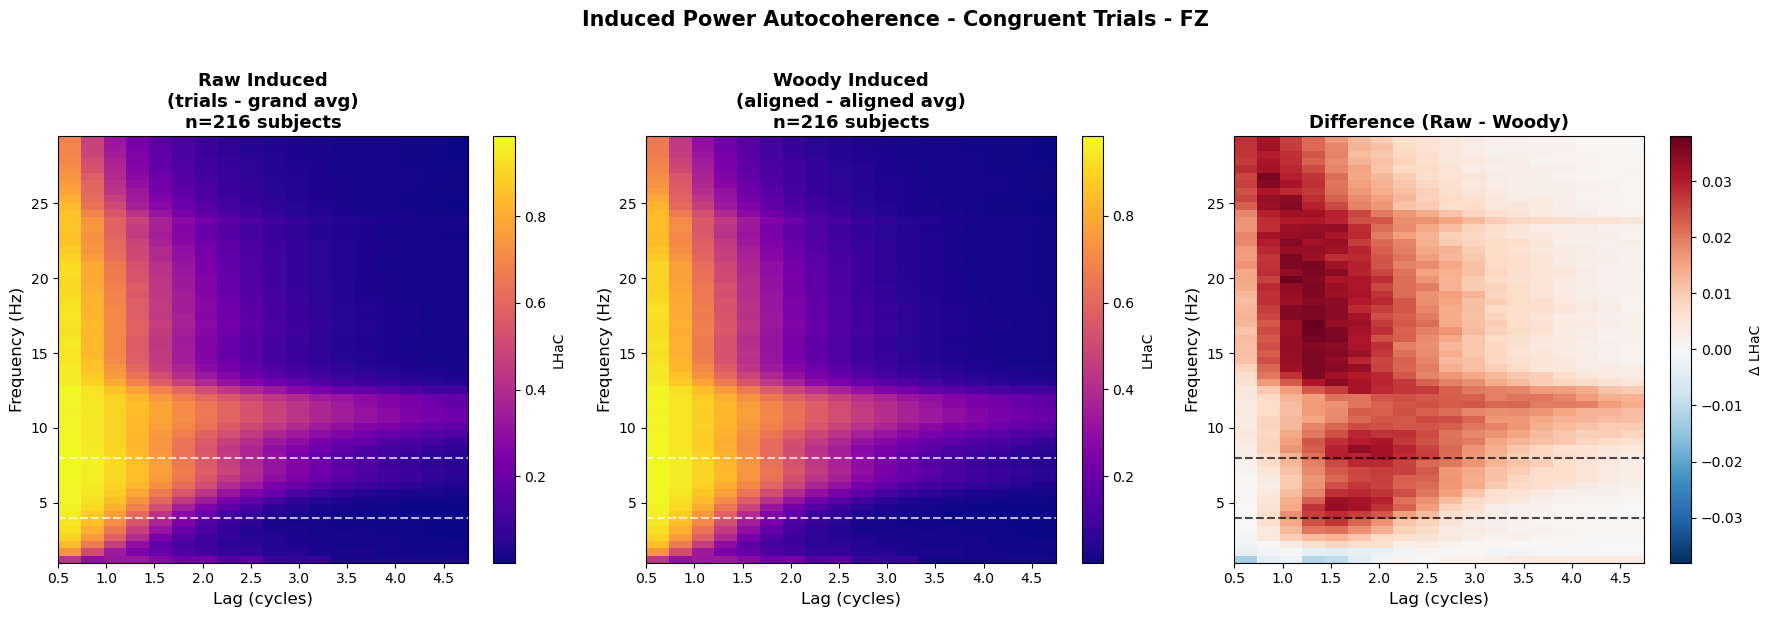

In [32]:
# Extract autocoherence data for induced power - INCONGRUENT
lcs_incong_raw_all = []
lcs_incong_woody_all = []

for result in all_results_flanker:
    # Average over trials for each subject
    lcs_incong_raw_all.append(result['lcs_incong_raw'].mean(axis=0))  # (n_freqs, n_lags)
    lcs_incong_woody_all.append(result['lcs_incong_woody'].mean(axis=0))

# Convert to arrays and average across subjects
lcs_incong_raw_all = np.array(lcs_incong_raw_all)
lcs_incong_woody_all = np.array(lcs_incong_woody_all)

lhc_incong_raw_mean = lcs_incong_raw_all.mean(axis=0)
lhc_incong_woody_mean = lcs_incong_woody_all.mean(axis=0)
lhc_incong_diff = lhc_incong_raw_mean - lhc_incong_woody_mean

# Extract autocoherence data for induced power - CONGRUENT
lcs_cong_raw_all = []
lcs_cong_woody_all = []

for result in all_results_flanker:
    # Average over trials for each subject
    lcs_cong_raw_all.append(result['lcs_cong_raw'].mean(axis=0))  # (n_freqs, n_lags)
    lcs_cong_woody_all.append(result['lcs_cong_woody'].mean(axis=0))

# Convert to arrays and average across subjects
lcs_cong_raw_all = np.array(lcs_cong_raw_all)
lcs_cong_woody_all = np.array(lcs_cong_woody_all)

lhc_cong_raw_mean = lcs_cong_raw_all.mean(axis=0)
lhc_cong_woody_mean = lcs_cong_woody_all.mean(axis=0)
lhc_cong_diff = lhc_cong_raw_mean - lhc_cong_woody_mean

print(f"Group statistics (INDUCED - INCONGRUENT):")
print(f"  Raw induced - mean: {lhc_incong_raw_mean.mean():.3f}, max: {lhc_incong_raw_mean.max():.3f}")
print(f"  Woody induced - mean: {lhc_incong_woody_mean.mean():.3f}, max: {lhc_incong_woody_mean.max():.3f}")
print(f"  Difference - mean: {lhc_incong_diff.mean():.3f}, max: {lhc_incong_diff.max():.3f}")

print(f"\nGroup statistics (INDUCED - CONGRUENT):")
print(f"  Raw induced - mean: {lhc_cong_raw_mean.mean():.3f}, max: {lhc_cong_raw_mean.max():.3f}")
print(f"  Woody induced - mean: {lhc_cong_woody_mean.mean():.3f}, max: {lhc_cong_woody_mean.max():.3f}")
print(f"  Difference - mean: {lhc_cong_diff.mean():.3f}, max: {lhc_cong_diff.max():.3f}")

# === PLOT 1: INCONGRUENT ===
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_incong_raw_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Raw Induced\n(trials - grand avg)\nn={len(all_results_flanker)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_incong_woody_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Woody Induced\n(aligned - aligned avg)\nn={len(all_results_flanker)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Difference (Raw - Woody)
im3 = axes[2].imshow(lhc_incong_diff, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=-np.abs(lhc_incong_diff).max(), vmax=np.abs(lhc_incong_diff).max())
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('Difference (Raw - Woody)', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle('Induced Power Autocoherence - Incongruent Trials - FZ', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: CONGRUENT ===
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_cong_raw_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Raw Induced\n(trials - grand avg)\nn={len(all_results_flanker)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_cong_woody_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Woody Induced\n(aligned - aligned avg)\nn={len(all_results_flanker)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Difference (Raw - Woody)
im3 = axes[2].imshow(lhc_cong_diff, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=-np.abs(lhc_cong_diff).max(), vmax=np.abs(lhc_cong_diff).max())
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('Difference (Raw - Woody)', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle('Induced Power Autocoherence - Congruent Trials - FZ', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pickle
from pathlib import Path

# ============================================================================
# CREATE OUTPUT DIRECTORY
# ============================================================================

output_dir = Path("/Users/qmoreau/Documents/ERN_sim/autocoherence_results/")
output_dir.mkdir(parents=True, exist_ok=True)

In [40]:
# Pre-response period (-5 to 0s)
np.save(output_dir / "group_lhc_raw_error_pre.npy", lhc_raw_error_pre)
np.save(output_dir / "group_lhc_raw_correct_pre.npy", lhc_raw_correct_pre)
np.save(output_dir / "group_lhc_raw_diff_pre.npy", lhc_raw_diff_pre)

np.save(output_dir / "group_lhc_woody_error_pre.npy", lhc_woody_error_pre)
np.save(output_dir / "group_lhc_woody_correct_pre.npy", lhc_woody_correct_pre)
np.save(output_dir / "group_lhc_woody_diff_pre.npy", lhc_woody_diff_pre)

# Post-response period (0 to +5s)
np.save(output_dir / "group_lhc_raw_error_post.npy", lhc_raw_error_post)
np.save(output_dir / "group_lhc_raw_correct_post.npy", lhc_raw_correct_post)
np.save(output_dir / "group_lhc_raw_diff_post.npy", lhc_raw_diff_post)

np.save(output_dir / "group_lhc_woody_error_post.npy", lhc_woody_error_post)
np.save(output_dir / "group_lhc_woody_correct_post.npy", lhc_woody_correct_post)
np.save(output_dir / "group_lhc_woody_diff_post.npy", lhc_woody_diff_post)

In [41]:
# Pre-response - subject-level matrices (averaged over trials)
np.save(output_dir / "subjects_lhc_raw_error_pre.npy", lcs_raw_error_pre)
np.save(output_dir / "subjects_lhc_raw_correct_pre.npy", lcs_raw_correct_pre)
np.save(output_dir / "subjects_lhc_woody_error_pre.npy", lcs_woody_error_pre)
np.save(output_dir / "subjects_lhc_woody_correct_pre.npy", lcs_woody_correct_pre)

# Post-response - subject-level matrices
np.save(output_dir / "subjects_lhc_raw_error_post.npy", lcs_raw_error_post)
np.save(output_dir / "subjects_lhc_raw_correct_post.npy", lcs_raw_correct_post)
np.save(output_dir / "subjects_lhc_woody_error_post.npy", lcs_woody_error_post)
np.save(output_dir / "subjects_lhc_woody_correct_post.npy", lcs_woody_correct_post)
